# **OPT-ResNet50**

In [1]:
# ── Librerías ────────────────────────────────────────────────────────────────────
import os
import gc
import random
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from pathlib import Path
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from optuna.trial import TrialState
from tqdm.auto import tqdm as _tqdm
import pynvml
import time
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
# Verificar GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.set_logical_device_configuration(
        gpus[0],
        [tf.config.LogicalDeviceConfiguration(memory_limit=15360)]  # Límite de 15 GB
    )
    print(f'GPU encontrada: {gpus[0].name} (límite 15GB)')
else:
    print('No se encontró GPU, corriendo en CPU')

GPU encontrada: /physical_device:GPU:0 (límite 15GB)


-------------
## **Búsqueda de Hiperparámetros**
---------------

In [3]:
# ── Rutas ────────────────────────────────────────────────────────────────────
REPO_ROOT   = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
DATA_PATH   = Path.home() / 'pfc' / 'Dataset Sintetico 352x192'
MODELS_PATH = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 1' / 'ResNet50'
MODELS_PATH.mkdir(parents=True, exist_ok=True)

In [4]:
# ── Experimento ────────────────────────────────────────────────────────────
EXPERIMENT_NAME  = 'OPT-RN50'
ARQUITECTURA     = 'ResNet50'
DATASET          = 'Sintético'

# ── Imagen ────────────────────────────────────────────────────────────────────
IMG_HEIGHT    = 192
IMG_WIDTH     = 352
NUM_CLASSES   = 5
CLASSES       = ['CD', 'HYP', 'MI', 'NORM', 'STTC']
CHANNELS      = 3   # ResNet50 recibe imágenes RGB

# ── Entrenamiento ─────────────────────────────────────────────────────────────
LOSS_FUNCTION  = 'sparse_categorical_crossentropy'
BATCH_SIZE     = 32
N_TRIALS       = 20
EPOCH_MAX      = 100
SEED           = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED']         = str(SEED)
os.environ['TF_DETERMINISTIC_OPS']   = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
tf.config.experimental.enable_op_determinism()

# ── Callbacks ─────────────────────────────────────────────────────────────────
# Early Stopping (fase FT)
ES_PATIENCE  = 8
ES_MIN_DELTA = 0.0001
METRIC       = 'val_loss'
DIRECTION    = 'minimize'
# Pruner
N_STARTUP_TRIALS    = 8    # trials completos antes de que el pruner actúe
N_WARMUP_STEPS      = 10   # epochs de FT antes de que el pruner pueda podar dentro de un trial
INTERVAL_STEPS      = 1
N_MIN_TRIALS_PRUNER = 3
# ReduceLROnPlateau (fase FT)
RLR_FACTOR    = 0.5
RLR_PATIENCE  = 5
RLR_MIN_DELTA = 0.0001
RLR_MIN_LR    = 1e-7

# ── Optimizador ───────────────────────────────────────────────────────────────
WEIGHT_DECAY  = 1e-2   # AdamW, fijo para todas las fases
LP_LR         = 1e-3   # LR fijo para la fase LP (no buscado por Optuna)
LP_EPOCHS     = 10     # Épocas de Linear Probing (solo cabeza, backbone congelado)

# ── Espacios de búsqueda (Optuna) ─────────────────────────────────────────────
DENSE_UNITS_OPTS = [128, 256]
FT_BLOCKS_OPTS   = [1, 2]         # 1: conv5_block3 | 2: conv5_block2+block3
LR_FT_RANGE      = (1e-6, 1e-4)

### **Arquitectura**

ResNet50 está organizada en un stem convolucional seguido de 4 stages de bloques residuales (`conv2`–`conv5`), con 3, 4, 6 y 3 bloques respectivamente — 16 bloques en total (23.6M parámetros).

El entrenamiento sigue un protocolo **LP-FT** de dos fases:
- **Fase LP** (`LP_EPOCHS` épocas): backbone completamente congelado, solo se entrena la cabeza clasificadora con `LP_LR = 1e-3`.
- **Fase FT** (hasta `EPOCH_MAX` épocas con early stopping): se descongelan los últimos bloques de `conv5` según `ft_blocks`, y se continúa entrenando con `learning_rate_ft` sugerido por Optuna.

El hiperparámetro `ft_blocks` define cuántos bloques del final de `conv5` se descongelan en la fase FT:
- `ft_blocks=1`: solo `conv5_block3` (≈19% de los parámetros del backbone)
- `ft_blocks=2`: `conv5_block2` + `conv5_block3` (≈38% de los parámetros del backbone)

In [8]:
# ── Bloques residuales de ResNet50 ───────────────────────────────────────────
RESNET50_BLOCK_NAMES = [
    f'conv{stage}_block{b}'
    for stage, n_blocks in zip([2, 3, 4, 5], [3, 4, 6, 3])
    for b in range(1, n_blocks + 1)
]
RESNET50_TOTAL_BLOCKS = len(RESNET50_BLOCK_NAMES)  # 16

# ── Bloques a descongelar por opción de ft_blocks ─────────────────────────────
FINE_TUNE_BLOCKS = {
    1: ['conv5_block3'],                    # último bloque de conv5  (~19% params)
    2: ['conv5_block2', 'conv5_block3'],    # últimos 2 bloques de conv5 (~38% params)
}

def set_fine_tune_layers(backbone, ft_blocks):
    prefixes = [b + '_' for b in FINE_TUNE_BLOCKS[ft_blocks]]
    for layer in backbone.layers:
        layer.trainable = any(layer.name.startswith(p) for p in prefixes)

for n, blocks in FINE_TUNE_BLOCKS.items():
    print(f'ft_blocks={n}: {blocks}')

ft_blocks=1: ['conv5_block3']
ft_blocks=2: ['conv5_block2', 'conv5_block3']


In [9]:
def build_resnet50(dense_units, input_shape=(192, 352, 3), num_classes=5):
    inputs = tf.keras.Input(shape=input_shape)

    # ── Base ResNet50 preentrenada — backbone completamente congelado ─────────
    base = tf.keras.applications.ResNet50(
        include_top = False,
        weights     = 'imagenet',
        input_shape = input_shape,
    )
    base.trainable = False

    # training=False: BatchNorm del backbone siempre en modo inferencia
    x = base(inputs, training=False)

    # ── Cabeza clasificadora ──────────────────────────────────────────────────
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(num_classes, activation='softmax')(x)

    return tf.keras.Model(inputs=inputs, outputs=x, name='ResNet50_FT'), base

### **Carga de Datos**

In [10]:
# Carga de datos con tf.data — preprocesamiento para ResNet50
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(directory, shuffle):
    ds = tf.keras.utils.image_dataset_from_directory(
        directory,
        image_size  = (IMG_HEIGHT, IMG_WIDTH),
        color_mode  = 'grayscale',
        class_names = CLASSES,
        batch_size  = BATCH_SIZE,
        shuffle     = shuffle,
        seed        = SEED if shuffle else None,
        label_mode  = 'int',
    )
    def preprocess(x, y):
        x = tf.repeat(x, 3, axis=-1)                           # Grayscale (1 canal) → RGB (3 canales)
        x = tf.keras.applications.resnet.preprocess_input(x)   # Normalización con medias de ImageNet
        return x, y
    return (
        ds.map(preprocess, num_parallel_calls=AUTOTUNE)
          .prefetch(AUTOTUNE)
    )

# NOTA: train_data y val_data se instancian dentro de objective()
# Esto garantiza que cada trial parta del estado inicial del shuffle (época 0),
# eliminando variabilidad por estado acumulado del dataset entre trials.

test_data = make_dataset(DATA_PATH / 'test', shuffle=False)
print('Clases:', CLASSES)

Found 10258 files belonging to 5 classes.
Clases: ['CD', 'HYP', 'MI', 'NORM', 'STTC']


### **Estudio de Optuna**

In [11]:
class OptunaPruningCallback(tf.keras.callbacks.Callback):
    def __init__(self, trial, monitor='val_loss'):
        super().__init__()
        self.trial   = trial
        self.monitor = monitor

    def on_epoch_end(self, epoch, logs=None):
        value = logs.get(self.monitor)
        if value is not None:
            self.trial.report(value, epoch)
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def objective(trial):
    tf.keras.backend.clear_session()
    gc.collect()
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    # ── Hiperparámetros ───────────────────────────────────────────────────────
    dense_units = trial.suggest_categorical('dense_units', DENSE_UNITS_OPTS)
    ft_blocks   = trial.suggest_categorical('ft_blocks',   FT_BLOCKS_OPTS)
    lr_ft       = trial.suggest_float('learning_rate_ft',  *LR_FT_RANGE, log=True)

    # ── Dataset fresco para este trial ────────────────────────────────────────
    train_data = make_dataset(DATA_PATH / 'train', shuffle=True)
    val_data   = make_dataset(DATA_PATH / 'val',   shuffle=False)

    model, base = build_resnet50(
        dense_units = dense_units,
        input_shape = (IMG_HEIGHT, IMG_WIDTH, CHANNELS),
        num_classes = NUM_CLASSES,
    )

    # ── Fase 1: LP — backbone congelado, solo entrena la cabeza ──────────────────
    model.compile(
        optimizer = tf.keras.optimizers.AdamW(learning_rate=LP_LR, weight_decay=WEIGHT_DECAY),
        loss      = LOSS_FUNCTION,
        metrics   = ['accuracy'],
    )
    model.fit(
        train_data,
        validation_data = val_data,
        epochs          = LP_EPOCHS,
        verbose         = 0,
    )

    # ── Fase 2: FT — descongelar bloques seleccionados ────────────────────────
    set_fine_tune_layers(base, ft_blocks)

    model.compile(
        optimizer = tf.keras.optimizers.AdamW(learning_rate=lr_ft, weight_decay=WEIGHT_DECAY),
        loss      = LOSS_FUNCTION,
        metrics   = ['accuracy'],
    )
    history = model.fit(
        train_data,
        validation_data = val_data,
        epochs          = EPOCH_MAX,
        callbacks       = [
            EarlyStopping(
                monitor              = METRIC,
                patience             = ES_PATIENCE,
                min_delta            = ES_MIN_DELTA,
                restore_best_weights = True,
            ),
            ReduceLROnPlateau(
                monitor   = METRIC,
                factor    = RLR_FACTOR,
                patience  = RLR_PATIENCE,
                min_delta = RLR_MIN_DELTA,
                min_lr    = RLR_MIN_LR,
            ),
            OptunaPruningCallback(trial, monitor=METRIC),
        ],
        verbose = 0,
    )

    trial.set_user_attr('epochs_trained', LP_EPOCHS + len(history.history[METRIC]))
    return min(history.history[METRIC])

In [12]:
_db_path = MODELS_PATH / (EXPERIMENT_NAME + '.db')

study = optuna.create_study(
    direction      = DIRECTION,
    study_name     = EXPERIMENT_NAME,
    storage        = f'sqlite:///{_db_path}',
    load_if_exists = True,
    sampler        = optuna.samplers.TPESampler(seed=SEED, n_startup_trials=N_STARTUP_TRIALS),
    pruner         = optuna.pruners.MedianPruner(
        n_startup_trials = N_STARTUP_TRIALS,
        n_warmup_steps   = N_WARMUP_STEPS,
        n_min_trials     = N_MIN_TRIALS_PRUNER,
        interval_steps   = INTERVAL_STEPS,
    ),
)

# ── Reintentar último trial fallido ───────────────────────────────────────────
_all_trials = study.trials
_zombies = [t for t in _all_trials if t.state == TrialState.RUNNING]
if _zombies:
    for t in _zombies:
        try:
            study._storage.set_trial_state_values(t._trial_id, TrialState.FAIL, {})
        except Exception:
            pass
    _all_trials = study.trials

_failed = [t for t in _all_trials if t.state == TrialState.FAIL and t.params]
if _failed:
    last_failed = max(_failed, key=lambda t: t.number)
    last_done   = max((t.number for t in _all_trials if t.state in (TrialState.COMPLETE, TrialState.PRUNED)), default=-1)
    if last_failed.number > last_done:
        print(f'  Trial {last_failed.number} fallido → reintento')
        study.enqueue_trial(last_failed.params)

# ── Pre-encolar startup trials (evita duplicados al reiniciar el kernel) ──────
import optuna.distributions as _dist
_shadow = optuna.create_study(
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=N_STARTUP_TRIALS)
)
_distributions = {
    'dense_units':      _dist.CategoricalDistribution(DENSE_UNITS_OPTS),
    'ft_blocks':        _dist.CategoricalDistribution(FT_BLOCKS_OPTS),
    'learning_rate_ft': _dist.FloatDistribution(*LR_FT_RANGE, log=True),
}
_startup_proposals = []
for _ in range(N_STARTUP_TRIALS):
    _t = _shadow.ask(_distributions)
    _startup_proposals.append(dict(_t.params))
    _shadow.tell(_t, 0.5)

_done_params = [t.params for t in study.trials
                if t.state in (TrialState.COMPLETE, TrialState.PRUNED, TrialState.WAITING)]
for _p in _startup_proposals:
    if not any(_p['dense_units'] == d.get('dense_units') and
               _p['ft_blocks'] == d.get('ft_blocks') and
               _p['learning_rate_ft'] == d.get('learning_rate_ft')
               for d in _done_params):
        study.enqueue_trial(_p)

# ── Trials restantes ──────────────────────────────────────────────────────────
n_completados = len([t for t in study.trials
                     if t.state in (TrialState.COMPLETE, TrialState.PRUNED)])
n_restantes   = max(0, N_TRIALS - n_completados)
print(f'Trials completados: {n_completados} — Trials restantes: {n_restantes}')

# ── Progress bar ──────────────────────────────────────────────────────────────
_pbar = _tqdm(total=N_TRIALS, initial=n_completados, desc='Optuna', unit='trial')

def _trial_callback(study, trial):
    n_done = len([t for t in study.trials
                  if t.state in (TrialState.COMPLETE, TrialState.PRUNED)])
    if trial.state == TrialState.COMPLETE:
        _pbar.update(1)
        best = study.best_trial
        _pbar.set_postfix({
            'mejor_trial': best.number,
            'mejor_loss':  f'{best.value:.4f}',
            'ultimo':      f'{trial.value:.4f}',
        })
        print(f'Trial {trial.number:>3} | val_loss={trial.value:.4f} | mejor={best.value:.4f} (t{best.number}) | {n_done}/{N_TRIALS}')
    elif trial.state == TrialState.PRUNED:
        _pbar.update(1)
        _pbar.set_postfix({'ultimo': 'podado'})
        print(f'Trial {trial.number:>3} | PODADO | {n_done}/{N_TRIALS}')
    elif trial.state == TrialState.FAIL:
        _pbar.set_postfix({'ultimo': 'FAILED'})
        print(f'Trial {trial.number:>3} | FAILED | {n_done}/{N_TRIALS}')

study.optimize(
    objective,
    n_trials          = n_restantes,
    show_progress_bar = False,
    gc_after_trial    = True,
    catch             = (tf.errors.ResourceExhaustedError,),
    callbacks         = [_trial_callback],
)
_pbar.close()

  Trial 20 fallido → reintento
Trials completados: 19 — Trials restantes: 1


Optuna:  95%|#########5| 19/20 [00:00<?, ?trial/s]

Found 46497 files belonging to 5 classes.
Found 11624 files belonging to 5 classes.
Trial  21 | val_loss=0.8698 | mejor=0.8272 (t8) | 20/20


In [13]:
# ── Cargar estudio ──────────────────────────────────────────────────────────────
study = optuna.load_study(
    study_name = EXPERIMENT_NAME,
    storage    = f'sqlite:///{_db_path}',
)
df_study = study.trials_dataframe()
display(df_study)

# ── Guardar csv ──────────────────────────────────────────────────────────────
df_clean = df_study[df_study['state'].isin(['COMPLETE', 'PRUNED'])].copy()
df_clean = df_clean.reset_index(drop=True)
df_clean.index = df_clean.index + 1
df_clean.index.name = 'trial'

param_cols = sorted([c for c in df_clean.columns if c.startswith('params_')])
cols_order = ['value', 'state', 'datetime_start', 'datetime_complete',
              'duration', 'user_attrs_epochs_trained'] + param_cols
df_clean = df_clean[[c for c in cols_order if c in df_clean.columns]]
df_clean = df_clean.rename(columns={
    'datetime_start':            't_start',
    'datetime_complete':         't_finish',
    'user_attrs_epochs_trained': 'epochs_trained',
    **{c: c.replace('params_', '') for c in param_cols}
})
for col in ['t_start', 't_finish']:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].dt.strftime('%d/%m - %H:%M')
if 'duration' in df_clean.columns:
    df_clean['duration'] = df_clean['duration'].apply(
        lambda x: f"{int(x.total_seconds()//3600):02d}:{int((x.total_seconds()%3600)//60):02d}:{int(x.total_seconds()%60):02d}" if pd.notna(x) else ''
    )
df_clean.to_csv(MODELS_PATH / f'{EXPERIMENT_NAME}.csv')
print(f'CSV guardado: {len(df_clean)} trials')

,number,value,datetime_start,datetime_complete,duration,params_dense_units,params_ft_blocks,params_learning_rate_ft,user_attrs_epochs_trained,system_attrs_fixed_params,state
0,0,0.908547,2026-07-05 20:09:57.784145,2026-07-05 21:25:30.154380,0 days 01:15:32.370235,256,1,0.000002,34.0,"{'dense_units': 256, 'ft_blocks': 1, 'learning...",COMPLETE
1,1,0.900373,2026-07-05 21:25:30.440906,2026-07-05 22:11:29.841453,0 days 00:45:59.400547,128,1,0.000026,21.0,"{'dense_units': 128, 'ft_blocks': 1, 'learning...",COMPLETE
2,2,0.908536,2026-07-05 22:11:30.188754,2026-07-05 23:21:55.490342,0 days 01:10:25.301588,256,1,0.000002,32.0,"{'dense_units': 256, 'ft_blocks': 1, 'learning...",COMPLETE
3,3,0.904753,2026-07-05 23:21:55.882799,2026-07-06 00:18:54.941461,0 days 00:56:59.058662,256,1,0.000004,26.0,"{'dense_units': 256, 'ft_blocks': 1, 'learning...",COMPLETE
4,4,0.943659,2026-07-06 00:18:55.403040,2026-07-06 01:09:11.032688,0 days 00:50:15.629648,128,2,0.000008,22.0,"{'dense_units': 128, 'ft_blocks': 2, 'learning...",COMPLETE
5,5,0.964254,2026-07-06 01:09:11.552352,2026-07-06 02:20:26.774962,0 days 01:11:15.222610,128,2,0.000001,31.0,"{'dense_units': 128, 'ft_blocks': 2, 'learning...",COMPLETE
6,6,0.866511,2026-07-06 02:20:27.371712,2026-07-06 03:14:09.671215,0 days 00:53:42.299503,128,2,0.000085,23.0,"{'dense_units': 128, 'ft_blocks': 2, 'learning...",COMPLETE
7,7,0.953473,2026-07-06 03:14:10.525620,2026-07-06 04:05:31.969822,0 days 00:51:21.444202,128,2,0.000008,22.0,"{'dense_units': 128, 'ft_blocks': 2, 'learning...",COMPLETE
8,8,0.827201,2026-07-06 04:05:32.990551,2026-07-06 04:58:48.421350,0 days 00:53:15.430799,128,2,0.000087,23.0,NaN,COMPLETE
9,9,0.859418,2026-07-06 04:58:49.549306,2026-07-06 05:49:50.026281,0 days 00:51:00.476975,128,2,0.000065,22.0,NaN,COMPLETE


CSV guardado: 20 trials


In [12]:
import IPython

# ── Liberar memoria ───────────────────────────────────────────────────────────
print("Reiniciando kernel...")
IPython.Application.instance().kernel.do_shutdown(restart=True)

Reiniciando kernel...


{'status': 'ok', 'restart': True}

-------------
## **Resultados**
---------------

In [14]:
# ── Reconstruir contexto post-restart ─────────────────────────────────────────
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from optuna.trial import TrialState
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

REPO_ROOT       = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
MODELS_PATH     = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 1' / 'ResNet50'
EXPERIMENT_NAME = 'OPT-RN50'
DIRECTION       = 'minimize'

_db_path = MODELS_PATH / (EXPERIMENT_NAME + '.db')
study = optuna.load_study(
    study_name = EXPERIMENT_NAME,
    storage    = f'sqlite:///{_db_path}',
)

n_complete = len([t for t in study.trials if t.state == TrialState.COMPLETE])
n_pruned   = len([t for t in study.trials if t.state == TrialState.PRUNED])
print(f'Trials completos: {n_complete} | Podados: {n_pruned} | Mejor val_loss: {study.best_value:.4f} (trial {study.best_trial.number})')

Trials completos: 20 | Podados: 0 | Mejor val_loss: 0.8272 (trial 8)


### **Evolución del Estudio**

In [15]:
df_trials = pd.read_csv(MODELS_PATH / f'{EXPERIMENT_NAME}.csv', index_col='trial')

param_cols = [c for c in df_trials.columns if c not in
              ['value', 'state', 't_start', 't_finish', 'duration', 'epochs_trained']]

fmt = {'value': '{:.4f}'}
if 'learning_rate_ft' in df_trials.columns:
    fmt['learning_rate_ft'] = '{:.2e}'

display(df_trials.style.format(fmt, na_rep='-'))

,value,state,t_start,t_finish,duration,epochs_trained,dense_units,ft_blocks,learning_rate_ft
trial,,,,,,,,,
1,0.9085,COMPLETE,05/07 - 20:09,05/07 - 21:25,01:15:32,34.000000,256,1,2.05e-06
2,0.9004,COMPLETE,05/07 - 21:25,05/07 - 22:11,00:45:59,21.000000,128,1,2.61e-05
3,0.9085,COMPLETE,05/07 - 22:11,05/07 - 23:21,01:10:25,32.000000,256,1,2.31e-06
4,0.9048,COMPLETE,05/07 - 23:21,06/07 - 00:18,00:56:59,26.000000,256,1,3.82e-06
5,0.9437,COMPLETE,06/07 - 00:18,06/07 - 01:09,00:50:15,22.000000,128,2,8.17e-06
6,0.9643,COMPLETE,06/07 - 01:09,06/07 - 02:20,01:11:15,31.000000,128,2,1.24e-06
7,0.8665,COMPLETE,06/07 - 02:20,06/07 - 03:14,00:53:42,23.000000,128,2,8.54e-05
8,0.9535,COMPLETE,06/07 - 03:14,06/07 - 04:05,00:51:21,22.000000,128,2,7.59e-06
9,0.8272,COMPLETE,06/07 - 04:05,06/07 - 04:58,00:53:15,23.000000,128,2,8.69e-05


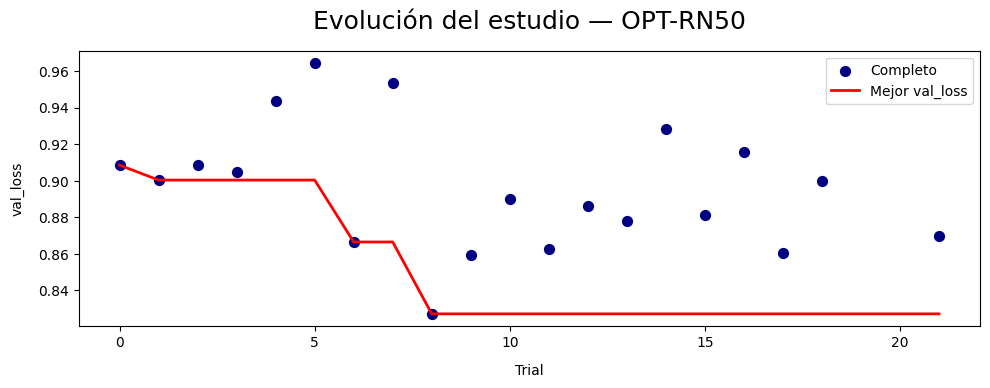

In [16]:
complete = [t for t in study.trials if t.state == TrialState.COMPLETE]
pruned   = [t for t in study.trials if t.state == TrialState.PRUNED]

fig, ax = plt.subplots(figsize=(10, 4))

if complete:
    ax.scatter([t.number for t in complete], [t.value for t in complete],
                color='navy', s=50, label='Completo')

if pruned:
    pruned_y = [list(t.intermediate_values.values())[-1] if t.intermediate_values else None
                for t in pruned]
    ax.scatter([t.number for t in pruned], pruned_y,
                color='orange', s=50, marker='x', label='Podado')

if complete:
    sorted_complete = sorted(complete, key=lambda t: t.number)
    best_so_far = pd.Series([t.value for t in sorted_complete]).cummin()
    ax.plot([t.number for t in sorted_complete], best_so_far,
            color='red', linewidth=2, label='Mejor val_loss')

ax.set_xlabel('Trial', labelpad=10)
ax.set_ylabel('val_loss', labelpad=10)
ax.set_title(f'Evolución del estudio — {EXPERIMENT_NAME}', fontsize=18, y=1.05)
ax.legend()
plt.tight_layout()
plt.show()

### **Análisis por Hiperparámetro**

In [17]:
try:
    import plotly
    fig = optuna.visualization.plot_param_importances(study)
    fig.update_traces(marker_color='navy')
    fig.update_layout(title=f'Importancia de hiperparámetros — {EXPERIMENT_NAME}')
    fig.show()
except ImportError:
    print('plotly no instalado — instalar con: pip install plotly')

/tmp/ipykernel_898088/452490950.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax_left.boxplot(
/tmp/ipykernel_898088/452490950.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax_left.boxplot(


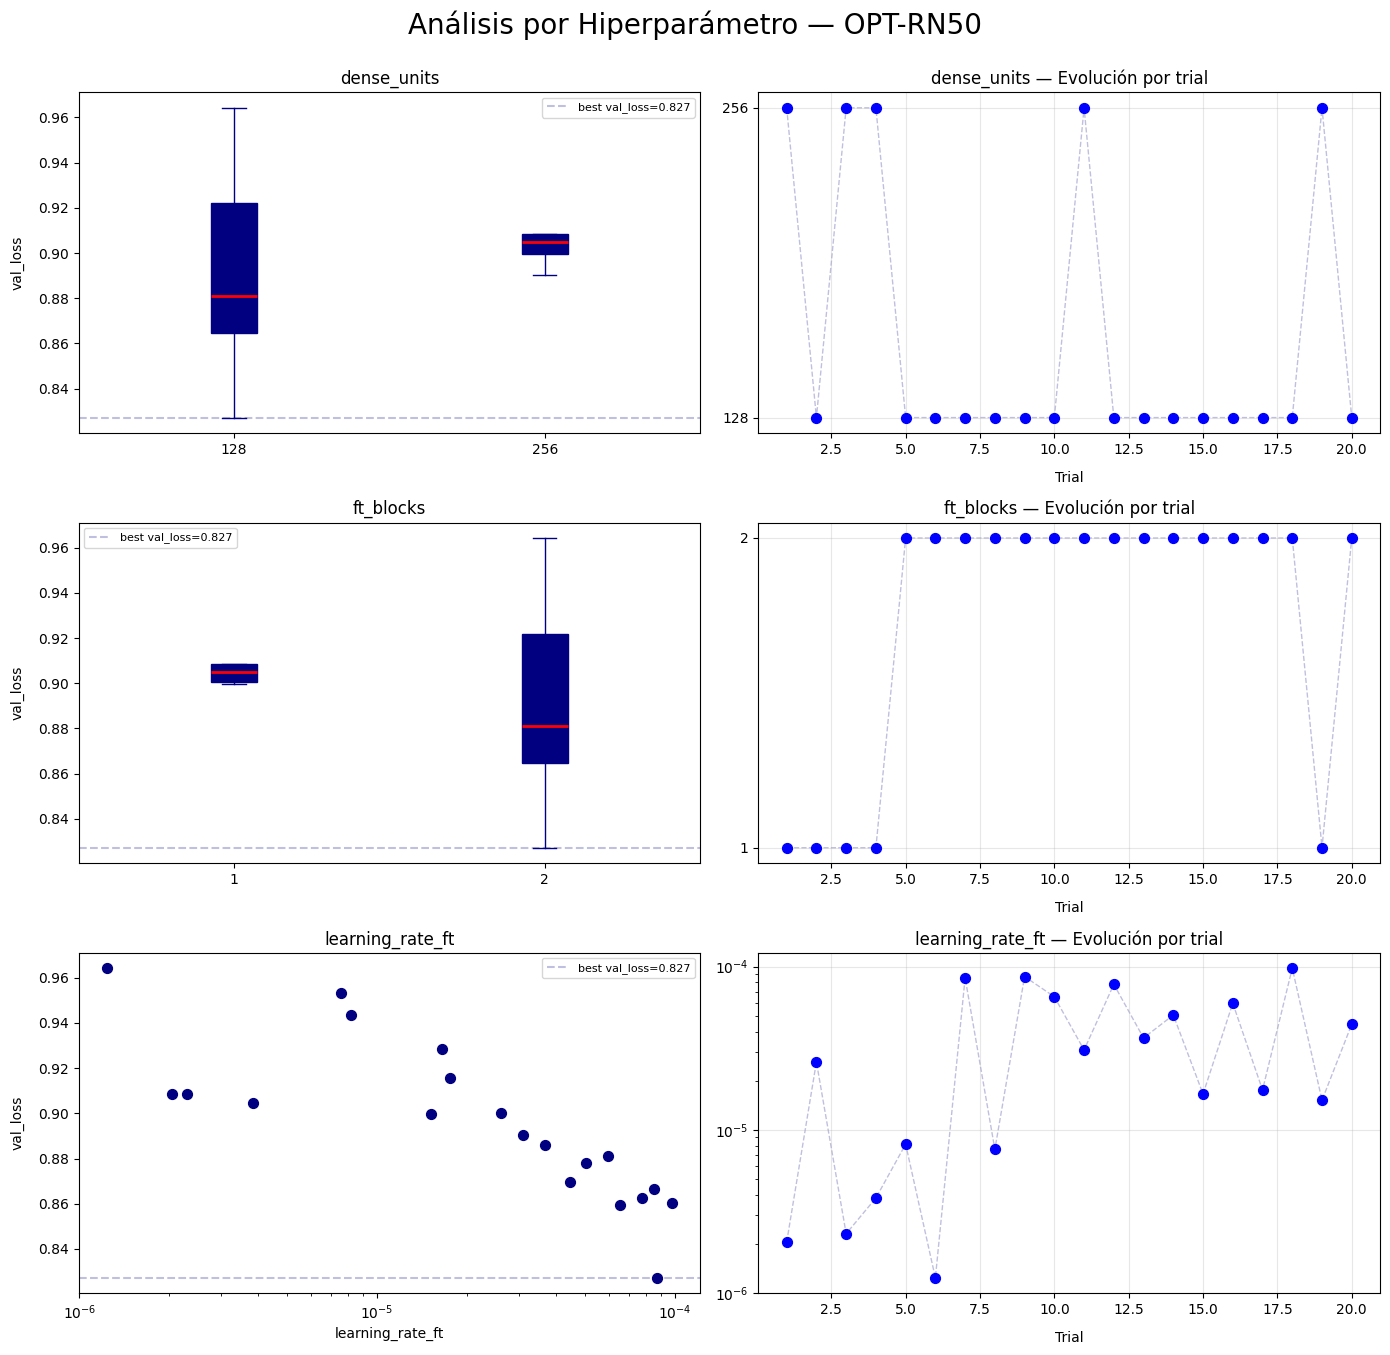

In [18]:
df_complete = df_trials[df_trials['state'] == 'COMPLETE'].copy()
df_complete['number'] = df_complete.index

n_params = len(param_cols)
fig, axes = plt.subplots(n_params, 2, figsize=(14, 4.5 * n_params))
if n_params == 1:
    axes = axes.reshape(1, 2)

for i, param in enumerate(param_cols):
    ax_left  = axes[i, 0]
    ax_right = axes[i, 1]

    is_cat = df_complete[param].dtype == object or df_complete[param].nunique() <= 6

    if is_cat:
        groups = sorted(df_complete[param].dropna().unique())
        data   = [df_complete[df_complete[param] == g]['value'].values for g in groups]
        ax_left.boxplot(
            data, labels=[str(g) for g in groups], patch_artist=True,
            boxprops    = dict(facecolor='navy', color='navy'),
            medianprops = dict(color='red', linewidth=2),
            whiskerprops= dict(color='navy'),
            capprops    = dict(color='navy'),
            flierprops  = dict(markerfacecolor='navy', markeredgecolor='navy', marker='o', markersize=4),
        )
    else:
        ax_left.scatter(df_complete[param], df_complete['value'], color='navy', s=50)
        if param == 'learning_rate_ft':
            ax_left.set_xscale('log')
        ax_left.set_xlabel(param)

    ax_left.axhline(study.best_value, color='navy', linestyle='--', alpha=0.25, linewidth=1.5,
                    label=f'best val_loss={study.best_value:.3f}')
    ax_left.set_ylabel('val_loss', labelpad=10)
    ax_left.set_title(param)
    ax_left.legend(fontsize=8)

    df_sorted = df_complete.sort_values('number')
    if is_cat:
        cats    = sorted(df_complete[param].dropna().unique())
        cat_map = {c: j for j, c in enumerate(cats)}
        y_vals  = df_sorted[param].map(cat_map)
        ax_right.plot(df_sorted['number'], y_vals, color='navy', alpha=0.25, linewidth=1, linestyle='--', zorder=1)
        ax_right.scatter(df_sorted['number'], y_vals, color='blue', s=50, zorder=2)
        ax_right.set_yticks(range(len(cats)))
        ax_right.set_yticklabels([str(c) for c in cats])
    else:
        ax_right.plot(df_sorted['number'], df_sorted[param], color='navy', alpha=0.25, linewidth=1, linestyle='--', zorder=1)
        ax_right.scatter(df_sorted['number'], df_sorted[param], color='blue', s=50, zorder=2)
        if param == 'learning_rate_ft':
            ax_right.set_yscale('log')

    ax_right.set_xlabel('Trial', labelpad=10)
    ax_right.set_title(f'{param} — Evolución por trial')
    ax_right.grid(True, alpha=0.3)

plt.suptitle(f'Análisis por Hiperparámetro — {EXPERIMENT_NAME}', fontsize=20, y=1)
plt.tight_layout()
plt.show()

### **Combinación de Hiperparámetros**

In [19]:
try:
    import plotly
    fig = optuna.visualization.plot_parallel_coordinate(study)
    fig.update_layout(title=f'Combinación de Hiperparámetros — {EXPERIMENT_NAME}')
    fig.show()
except ImportError:
    print('plotly no instalado')

In [20]:
df_ranked = df_trials[df_trials['state'].isin(['COMPLETE', 'PRUNED'])].sort_values('value')
display(df_ranked.style.format(fmt, na_rep='-'))

,value,state,t_start,t_finish,duration,epochs_trained,dense_units,ft_blocks,learning_rate_ft
trial,,,,,,,,,
9,0.8272,COMPLETE,06/07 - 04:05,06/07 - 04:58,00:53:15,23.000000,128,2,8.69e-05
10,0.8594,COMPLETE,06/07 - 04:58,06/07 - 05:49,00:51:00,22.000000,128,2,6.54e-05
18,0.8604,COMPLETE,06/07 - 11:34,06/07 - 12:28,00:54:14,23.000000,128,2,9.79e-05
12,0.8626,COMPLETE,06/07 - 06:36,06/07 - 07:27,00:51:15,22.000000,128,2,7.79e-05
7,0.8665,COMPLETE,06/07 - 02:20,06/07 - 03:14,00:53:42,23.000000,128,2,8.54e-05
20,0.8698,COMPLETE,06/07 - 17:04,06/07 - 19:13,02:09:11,21.000000,128,2,4.43e-05
14,0.8780,COMPLETE,06/07 - 08:16,06/07 - 09:05,00:48:50,21.000000,128,2,5.05e-05
16,0.8810,COMPLETE,06/07 - 09:56,06/07 - 10:45,00:48:43,21.000000,128,2,5.97e-05
13,0.8861,COMPLETE,06/07 - 07:27,06/07 - 08:16,00:49:09,21.000000,128,2,3.66e-05
